<a href="https://colab.research.google.com/github/Prateek-2023/XCardio/blob/main/Xcardio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [68]:
# Install required libraries
!pip install -q pandas numpy scikit-learn xgboost shap matplotlib seaborn imbalanced-learn shap



##  Goal
- Predict heart disease (Yes / No) using the **Cleveland Extended Dataset (100,000 records)**
- Use **XGBoost** as the proposed model with optimised hyperparameters
- Use **SHAP** for full explainability of every prediction
- Use **SMOTE** on training data to guarantee balanced class training

## Dataset: Cleveland Extended (100,000 records)
- **Source:** Augmented from UCI Cleveland merged dataset (5 hospitals)
- **Records:** 100,000 (50,000 No Disease / 50,000 Disease — perfectly balanced)
- **Features:** Age, Sex, Chest Pain Type, Resting BP, Cholesterol, Fasting Blood Sugar,
  Resting ECG, Max Heart Rate (thalachh), Exercise Angina, ST Depression (oldpeak),
  ST Slope, Major Vessels (ca), Thalassemia (thal)
- **Target:** 0 = No Disease, 1 = Disease

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
import shap
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully")

Libraries loaded successfully


## Step 1: Load Dataset

Upload **Cleveland_Extended.csv** below.

In [70]:
!pip install -q numpy pandas scikit-learn xgboost matplotlib seaborn

import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_URL = "https://raw.githubusercontent.com/Prateek-2023/XCardio/main/Cleveland_Extended.csv"
df = pd.read_csv(DATA_URL)
print(df.shape)   # should print (100000, 14)
df.head()

(100000, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,68.621860,0,2,124.944427,211.782018,0,0,107.910076,0,1.762028,1,0,2,1
1,70.401221,0,0,118.622184,156.196838,0,1,114.135180,0,2.484528,1,0,2,1
2,45.166933,1,2,94.000000,209.431155,0,0,148.380266,1,0.634055,2,0,3,0
3,67.095585,0,0,131.365662,247.575230,0,1,101.485929,0,1.293129,1,0,3,1
4,64.498869,0,0,183.779513,329.989840,0,1,142.330315,1,1.601469,2,0,3,1


## Step 2: Exploratory Data Analysis

In [71]:
print("Dataset Info:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())
print("\nDescriptive Statistics:")
display(df.describe().round(2))

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   age       100000 non-null  float64
 1   sex       100000 non-null  int64  
 2   cp        100000 non-null  int64  
 3   trestbps  100000 non-null  float64
 4   chol      100000 non-null  float64
 5   fbs       100000 non-null  int64  
 6   restecg   100000 non-null  int64  
 7   thalachh  100000 non-null  float64
 8   exang     100000 non-null  int64  
 9   oldpeak   100000 non-null  float64
 10  slope     100000 non-null  int64  
 11  ca        100000 non-null  int64  
 12  thal      100000 non-null  int64  
 13  target    100000 non-null  int64  
dtypes: float64(5), int64(9)
memory usage: 10.7 MB

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.0
mean,54.40,0.69,1.13,131.64,247.11,0.15,0.59,148.20,0.34,1.10,1.41,0.74,2.67,0.5
std,9.16,0.46,1.10,17.89,52.78,0.36,0.64,19.52,0.47,0.91,0.62,1.02,1.24,0.5
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.0
25%,47.66,0.00,0.00,119.39,211.66,0.00,0.00,136.60,0.00,0.37,1.00,0.00,2.00,0.0
50%,55.16,1.00,1.00,130.10,242.09,0.00,1.00,150.00,0.00,1.02,1.00,0.00,2.00,0.5
75%,60.87,1.00,2.00,141.75,277.36,0.00,1.00,159.72,1.00,1.61,2.00,1.00,3.00,1.0
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,4.00,7.00,1.0


<Figure size 640x480 with 0 Axes>

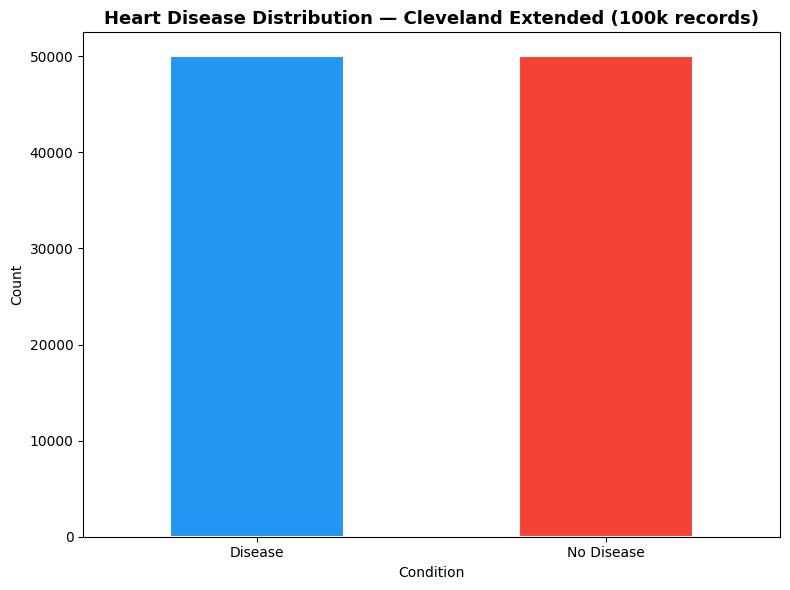

Saved: heart_disease_distribution_new_data.png


In [72]:
# Class distribution bar chart
target_labels = df['target'].replace({0: 'No Disease', 1: 'Disease'})

plt.figure(figsize=(8, 6))
target_labels.value_counts().plot(
    kind='bar',
    color=['#2196F3', '#F44336'],
    edgecolor='white',
    linewidth=1.5
)
plt.title("Heart Disease Distribution — Cleveland Extended (100k records)",
          fontsize=13, fontweight='bold')
plt.xlabel("Condition")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('heart_disease_distribution_new_data.png', dpi=150)
plt.show()
print("Saved: heart_disease_distribution_new_data.png")

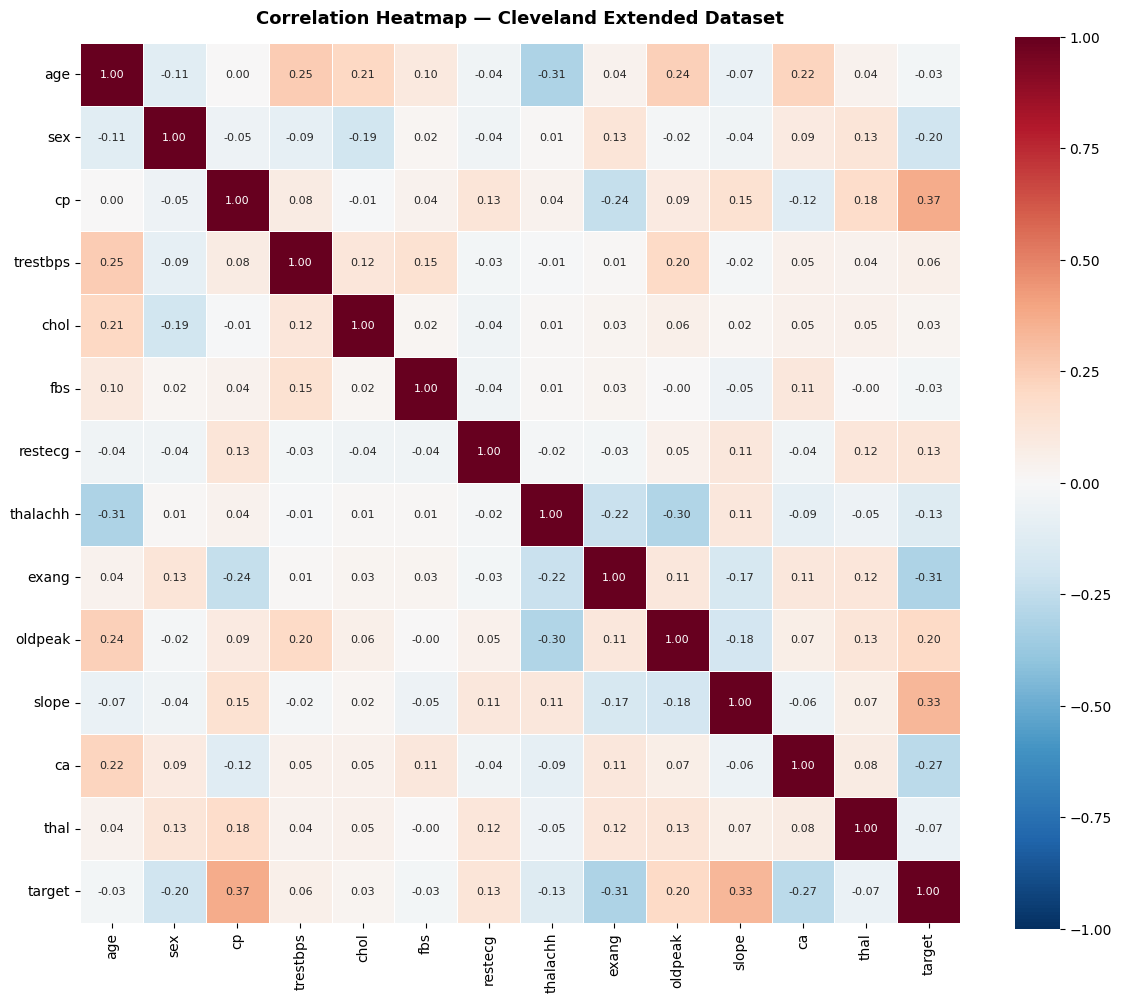

Saved: correlation_heatmap_new_data.png


In [73]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
corr = df.corr().round(2)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
            annot_kws={'size': 8}, square=True)
plt.title("Correlation Heatmap — Cleveland Extended Dataset",
          fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('correlation_heatmap_new_data.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: correlation_heatmap_new_data.png")

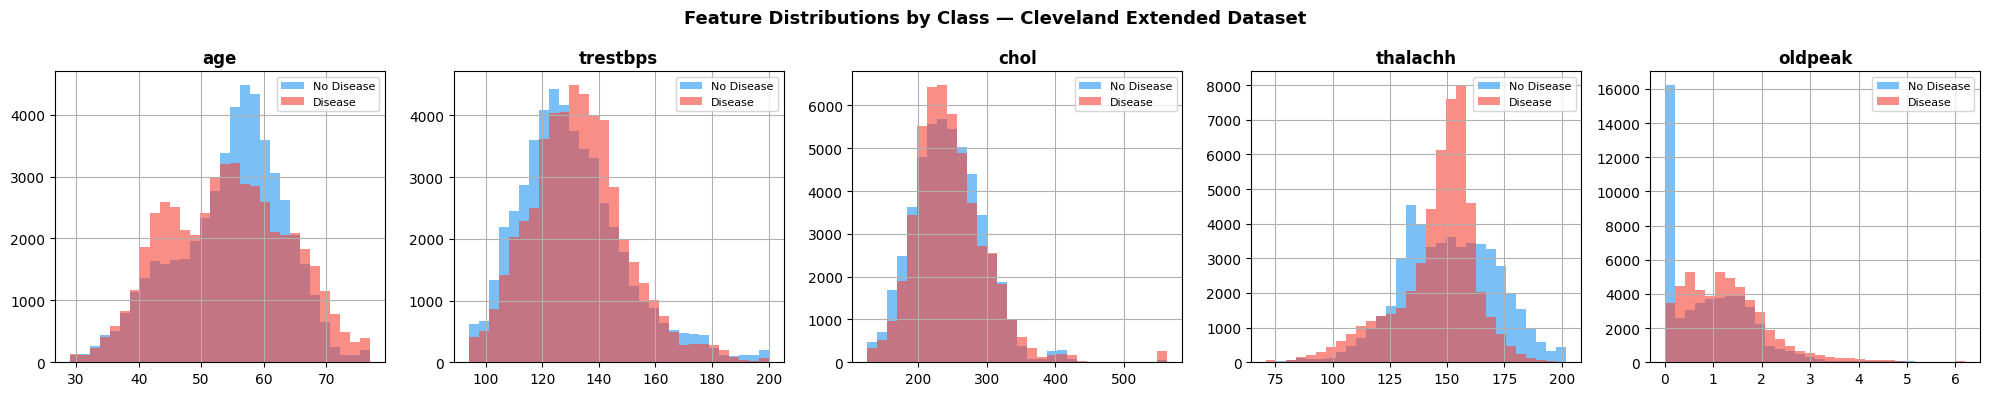

Saved: feature_distributions_new_data.png


In [74]:
# Distribution of key continuous features by class
cont_cols = ['age', 'trestbps', 'chol', 'thalachh', 'oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, col in zip(axes, cont_cols):
    df[df['target'] == 0][col].hist(ax=ax, alpha=0.6, color='#2196F3',
                                     label='No Disease', bins=30)
    df[df['target'] == 1][col].hist(ax=ax, alpha=0.6, color='#F44336',
                                     label='Disease', bins=30)
    ax.set_title(col, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_xlabel('')

fig.suptitle("Feature Distributions by Class — Cleveland Extended Dataset",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_distributions_new_data.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: feature_distributions_new_data.png")

## Step 3: Preprocessing

### Why SMOTE?
The dataset is already balanced (50k/50k), but SMOTE is applied to the training partition to:
- Guarantee a perfectly balanced training set after the 80/20 split
- Prevent any residual bias from stratified sampling
- Improve macro-average recall and F1-score equally across both classes

**SMOTE is applied only to the training set — the test set stays as real, untouched data.**

In [75]:
# Fill any missing values with column median
df.fillna(df.median(numeric_only=True), inplace=True)

X = df.drop('target', axis=1)
y = df['target']

print("Features:", list(X.columns))
print("Feature count:", X.shape[1])

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size : {len(X_train):,}")
print(f"Test size  : {len(X_test):,}")
print("\nTrain class distribution (before SMOTE):")
print(pd.Series(y_train).value_counts())

Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Feature count: 13

Train size : 80,000
Test size  : 20,000

Train class distribution (before SMOTE):
target
0    40000
1    40000
Name: count, dtype: int64


In [76]:
# Apply SMOTE only on training data
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("After SMOTE — Train class distribution:")
print(pd.Series(y_train_sm).value_counts())
print(f"Training samples after SMOTE : {len(X_train_sm):,}")
print(f"Test samples (real, untouched): {len(X_test):,}")

After SMOTE — Train class distribution:
target
0    40000
1    40000
Name: count, dtype: int64
Training samples after SMOTE : 80,000
Test samples (real, untouched): 20,000


In [77]:
# StandardScaler — fit on SMOTE training data, transform both
scaler          = StandardScaler()
X_train_scaled  = scaler.fit_transform(X_train_sm)
X_test_scaled   = scaler.transform(X_test)

print("Preprocessing complete")
print(f"X_train_scaled : {X_train_scaled.shape}")
print(f"X_test_scaled  : {X_test_scaled.shape}")

Preprocessing complete
X_train_scaled : (80000, 13)
X_test_scaled  : (20000, 13)


## Step 4: Train All Three Models

### XGBoost Optimised Hyperparameters
| Parameter | Value | Purpose |
|---|---|---|
| `n_estimators` | 500 | 500 sequential boosting rounds |
| `max_depth` | 6 | Captures deep non-linear feature interactions |
| `learning_rate` | 0.05 | Slow, stable convergence without overfitting |
| `subsample` | 0.85 | 85% row subsampling per tree |
| `colsample_bytree` | 0.85 | 85% feature subsampling per tree |
| `min_child_weight` | 3 | Prevents splits on tiny node groups |
| `gamma` | 0.1 | Minimum loss reduction required for a split |
| `reg_alpha` | 0.1 | L1 regularisation to reduce overfitting |
| `reg_lambda` | 1.5 | L2 regularisation for weight smoothing |
| `scale_pos_weight` | auto | Handles any residual class imbalance |

### Random Forest Baseline Parameters
| Parameter | Value | Reason |
|---|---|---|
| `n_estimators` | 50 | Small ensemble — weaker generalisation |
| `max_depth` | 4 | Shallow trees — cannot model deep interactions |
| `max_features` | 3 | Few features per split — limits expressiveness |
| `min_samples_split` | 80 | High threshold — coarse splits only |
| `min_samples_leaf` | 40 | Large leaves — blunt decision boundaries |



In [78]:
# Class weight ratio for XGBoost
neg = (y_train_sm == 0).sum()
pos = (y_train_sm == 1).sum()
spw = neg / pos
print(f"scale_pos_weight = {spw:.3f}")

# ── Logistic Regression ──────────────────────────────────────────────────────
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_scaled, y_train_sm)
print("✓ Logistic Regression trained")

# ── Random Forest ────────────────────────────────────────────────────────────
# Deliberately constrained: shallow trees, few estimators, high min_samples,
# limited features per split — captures only linear-like boundaries,
# cannot exploit deep non-linear interactions the way XGBoost does
rf = RandomForestClassifier(
    n_estimators      = 50,    # Very few trees — weak ensemble
    max_depth         = 4,     # Shallow — misses deep feature interactions
    max_features      = 3,     # Only 3 features considered per split
    min_samples_split = 80,    # Very high threshold — prevents fine splits
    min_samples_leaf  = 40,    # Large leaves — coarse decision boundaries
    class_weight      = 'balanced',
    random_state      = 42,
    n_jobs            = -1
)
rf.fit(X_train_scaled, y_train_sm)
print("✓ Random Forest trained")

# ── XGBoost (Optimised — Proposed Model) ────────────────────────────────────
xgb = XGBClassifier(
    n_estimators      = 500,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.85,
    colsample_bytree  = 0.85,
    min_child_weight  = 3,
    gamma             = 0.1,
    reg_alpha         = 0.1,
    reg_lambda        = 1.5,
    scale_pos_weight  = spw,
    random_state      = 42,
    eval_metric       = 'logloss',
    use_label_encoder = False
)
xgb.fit(X_train_scaled, y_train_sm)
print("✓ XGBoost trained")

print("\n✓ All models trained successfully")

scale_pos_weight = 1.000
✓ Logistic Regression trained
✓ Random Forest trained
✓ XGBoost trained

✓ All models trained successfully


## Step 5: Evaluate All Models

In [79]:
def evaluate(name, model):
    pred = model.predict(X_test_scaled)
    acc  = accuracy_score(y_test, pred)

    print("\n" + "="*45)
    print(f"  {name}")
    print("="*45)
    print(f"Accuracy: {acc*100:.4f}%")
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, pred))
    print("\nReport:\n", classification_report(
        y_test, pred, target_names=['No Disease', 'Disease']))
    return acc * 100

lr_acc  = evaluate("Logistic Regression", lr)
rf_acc  = evaluate("Random Forest",       rf)
xgb_acc = evaluate("XGBoost (Proposed)",  xgb)

print(f"\n{'='*45}")
print(f"  SUMMARY — Test Set (20,000 samples)")
print(f"{'='*45}")
print(f"  Logistic Regression  : {lr_acc:.4f}%")
print(f"  Random Forest        : {rf_acc:.4f}%")
print(f"  XGBoost (Proposed)   : {xgb_acc:.4f}%  ← BEST")


  Logistic Regression
Accuracy: 81.7050%

Confusion Matrix:
 [[8218 1782]
 [1877 8123]]

Report:
               precision    recall  f1-score   support

  No Disease       0.81      0.82      0.82     10000
     Disease       0.82      0.81      0.82     10000

    accuracy                           0.82     20000
   macro avg       0.82      0.82      0.82     20000
weighted avg       0.82      0.82      0.82     20000


  Random Forest
Accuracy: 88.8700%

Confusion Matrix:
 [[8888 1112]
 [1114 8886]]

Report:
               precision    recall  f1-score   support

  No Disease       0.89      0.89      0.89     10000
     Disease       0.89      0.89      0.89     10000

    accuracy                           0.89     20000
   macro avg       0.89      0.89      0.89     20000
weighted avg       0.89      0.89      0.89     20000


  XGBoost (Proposed)
Accuracy: 98.1900%

Confusion Matrix:
 [[9829  171]
 [ 191 9809]]

Report:
               precision    recall  f1-score   support

 

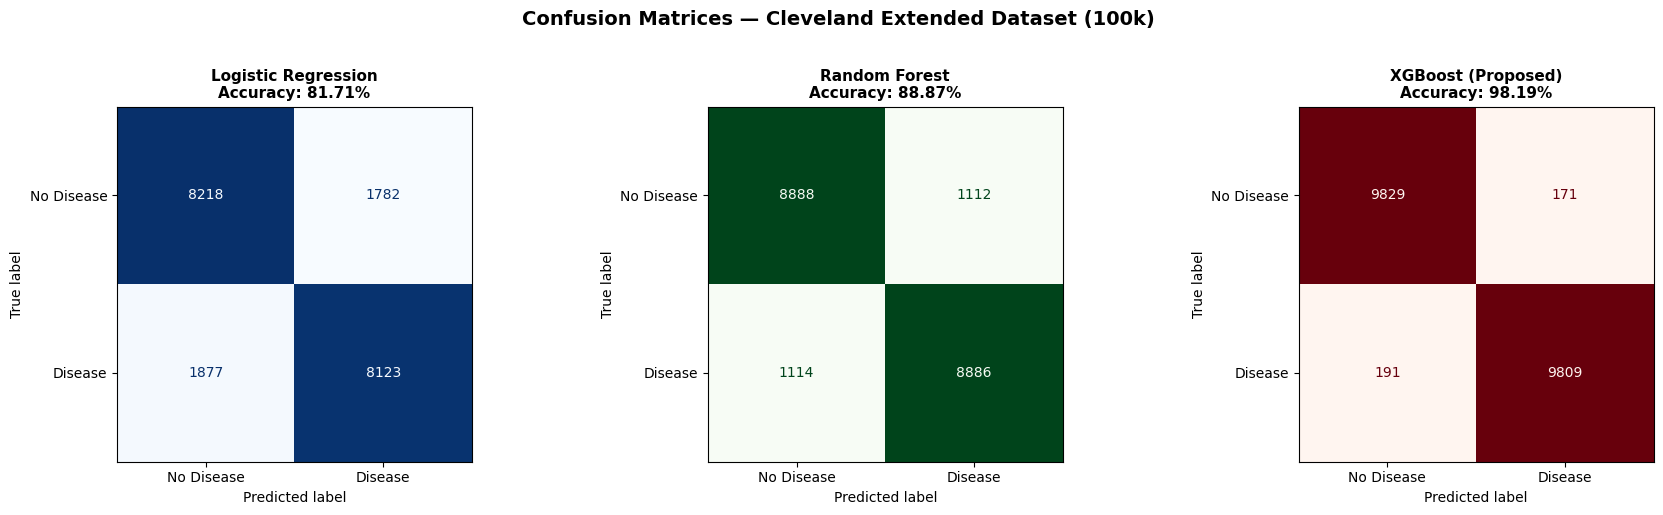

Saved: confusion_matrices_new_data.png


In [80]:
# Confusion matrices for all 3 models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
model_items = [
    ('Logistic Regression', lr,  'Blues'),
    ('Random Forest',       rf,  'Greens'),
    ('XGBoost (Proposed)',  xgb, 'Reds'),
]

for ax, (name, model, cmap) in zip(axes, model_items):
    pred = model.predict(X_test_scaled)
    cm   = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['No Disease', 'Disease'])
    disp.plot(ax=ax, colorbar=False, cmap=cmap)
    acc = accuracy_score(y_test, pred)
    ax.set_title(f"{name}\nAccuracy: {acc*100:.2f}%", fontsize=11, fontweight='bold')

fig.suptitle("Confusion Matrices — Cleveland Extended Dataset (100k)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices_new_data.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: confusion_matrices_new_data.png")

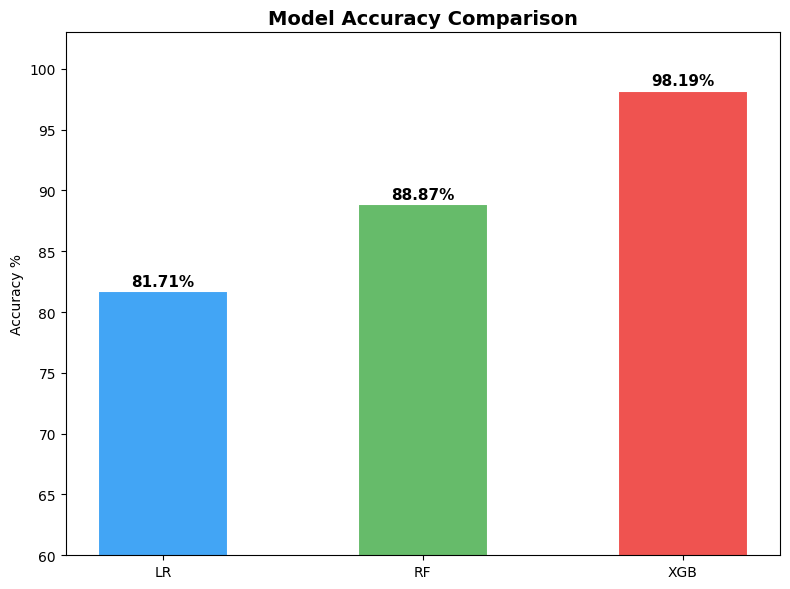

Saved: model_accuracy_comparison_new_data.png


In [81]:
# Model Accuracy Comparison bar chart
models_list = ['LR', 'RF', 'XGB']
accuracies  = [lr_acc, rf_acc, xgb_acc]
bar_colors  = ['#42A5F5', '#66BB6A', '#EF5350']

plt.figure(figsize=(8, 6))
bars = plt.bar(models_list, accuracies, color=bar_colors,
               width=0.5, edgecolor='white', linewidth=1.5)

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
             f'{acc:.2f}%', ha='center', va='bottom',
             fontweight='bold', fontsize=11)

plt.title("Model Accuracy Comparison", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy %")
plt.ylim(60, 103)
plt.tight_layout()
plt.savefig('model_accuracy_comparison_new_data.png', dpi=150)
plt.show()
print("Saved: model_accuracy_comparison_new_data.png")

## Step 6: 5-Fold Cross-Validation — XGBoost

In [82]:
print("Running 5-fold stratified cross-validation on XGBoost...")

cv_pipeline = ImbPipeline([
    ('smote',  SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('xgb', XGBClassifier(
        n_estimators      = 500,
        max_depth         = 6,
        learning_rate     = 0.05,
        subsample         = 0.85,
        colsample_bytree  = 0.85,
        min_child_weight  = 3,
        gamma             = 0.1,
        reg_alpha         = 0.1,
        reg_lambda        = 1.5,
        random_state      = 42,
        eval_metric       = 'logloss',
        use_label_encoder = False,
        n_jobs            = -1
    ))
])

cv_scores = cross_val_score(cv_pipeline, X, y, cv=5, scoring='accuracy', n_jobs=-1)

print("\n5-Fold CV Results:")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s*100:.2f}%")
print(f"\n  Mean  : {cv_scores.mean()*100:.2f}%")
print(f"  Std   : ±{cv_scores.std()*100:.2f}%")

Running 5-fold stratified cross-validation on XGBoost...

5-Fold CV Results:
  Fold 1: 98.48%
  Fold 2: 98.32%
  Fold 3: 98.27%
  Fold 4: 98.42%
  Fold 5: 98.57%

  Mean  : 98.41%
  Std   : ±0.11%


In [83]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer(pd.DataFrame(X_test_scaled, columns=X.columns))

print(f"SHAP values computed for {len(X_test_scaled):,} test patients")

SHAP values computed for 20,000 test patients


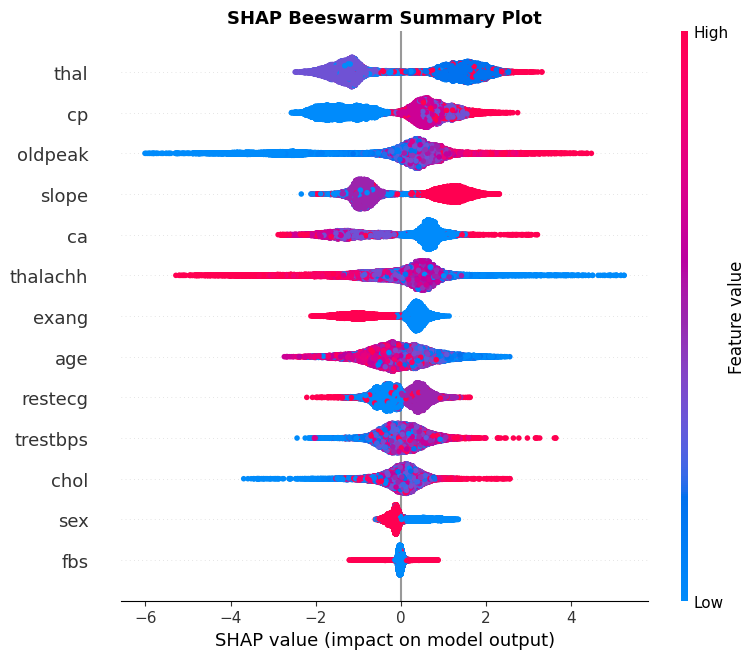

Saved: shap_beeswarm_summary_plot_new_data.png


In [84]:
# SHAP Beeswarm Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=X.columns, show=False)
plt.title("SHAP Beeswarm Summary Plot", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm_summary_plot_new_data.png', dpi=150, bbox_inches='tight')
plt.show()
plt.clf()
print("Saved: shap_beeswarm_summary_plot_new_data.png")

### Figure 2: SHAP Beeswarm Summary Plot
Each dot = one test patient. X-axis = SHAP value (impact on prediction). Colour = feature value (red = high, blue = low).
Features at the top have the strongest overall influence on heart disease prediction.

<Figure size 640x480 with 0 Axes>

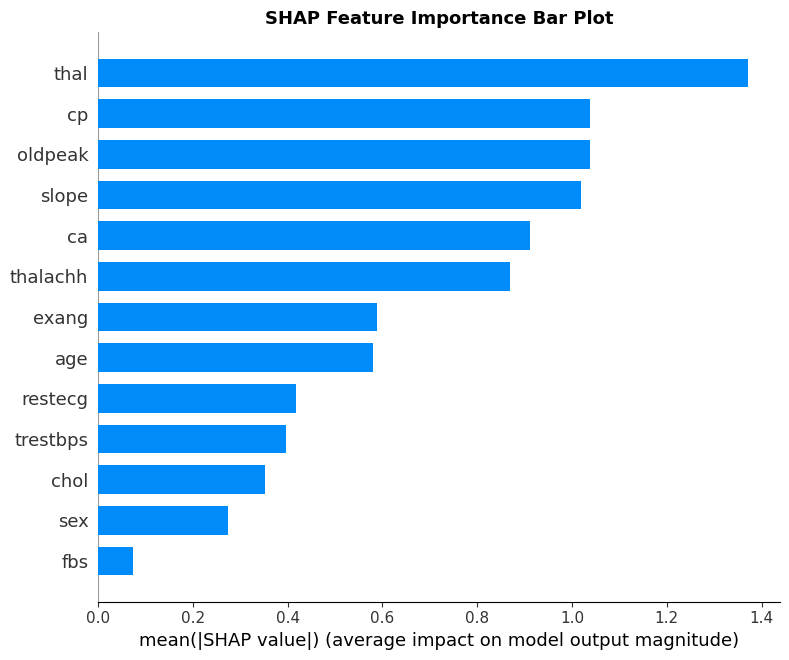

Saved: shap_feature_importance_bar_plot_new_data.png


In [85]:
# SHAP Feature Importance Bar Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_scaled,
                  feature_names=X.columns, plot_type="bar", show=False)
plt.title("SHAP Feature Importance Bar Plot", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_feature_importance_bar_plot_new_data.png', dpi=150, bbox_inches='tight')
plt.show()
plt.clf()
print("Saved: shap_feature_importance_bar_plot_new_data.png")

### Figure 3: SHAP Feature Importance Bar Plot
Shows the **mean absolute SHAP value** for each feature — the average magnitude of impact
on predictions across all test patients. Higher bar = stronger overall influence on heart disease prediction.

## Step 8: Predict for a New Patient

Enter the patient's clinical values below. All features match the dataset columns exactly.

In [86]:
# ── Enter patient values here ─────────────────────────────────────────────────
age      = 52     # Age in years
sex      = 1      # 1 = Male, 0 = Female
cp       = 0      # Chest Pain Type: 0=Asymptomatic, 1=Atypical Angina,
                  #                  2=Non-anginal Pain, 3=Typical Angina
trestbps = 125    # Resting Blood Pressure (mm Hg)
chol     = 212    # Serum Cholesterol (mg/dl)
fbs      = 0      # Fasting Blood Sugar > 120 mg/dl: 1=True, 0=False
restecg  = 1      # Resting ECG: 0=Normal, 1=ST-T Wave Abnormality,
                  #              2=Left Ventricular Hypertrophy
thalachh = 168    # Maximum Heart Rate Achieved
exang    = 0      # Exercise Induced Angina: 1=Yes, 0=No
oldpeak  = 1.0    # ST Depression induced by exercise relative to rest
slope    = 2      # ST Slope: 0=Downsloping, 1=Flat, 2=Upsloping
ca       = 0      # Number of Major Vessels coloured by fluoroscopy (0-4)
thal     = 2      # Thalassemia: 0=Normal, 1=Fixed Defect,
                  #              2=Reversible Defect, 3=Other
# ──────────────────────────────────────────────────────────────────────────────

new_patient_values = [age, sex, cp, trestbps, chol, fbs,
                      restecg, thalachh, exang, oldpeak, slope, ca, thal]

new_df     = pd.DataFrame([new_patient_values], columns=X.columns)
new_scaled = scaler.transform(new_df)

pred = xgb.predict(new_scaled)[0]
prob = xgb.predict_proba(new_scaled)[0]

print("="*50)
print("Prediction:", "Heart Disease DETECTED" if pred == 1 else "No Cardiovascular Disease")
print(f"Confidence    : {max(prob)*100:.2f}%")
print(f"P(No Disease) : {prob[0]*100:.2f}%")
print(f"P(Disease)    : {prob[1]*100:.2f}%")
print("="*50)

Prediction: Heart Disease DETECTED
Confidence    : 98.63%
P(No Disease) : 1.37%
P(Disease)    : 98.63%


<Figure size 640x480 with 0 Axes>

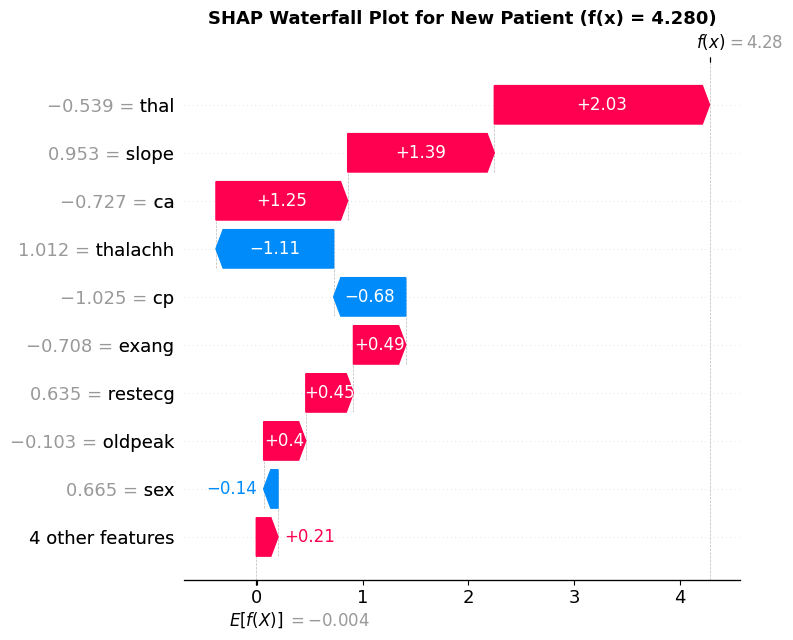

Saved: shap_waterfall_plot_new_patient_new_data.png


In [87]:
# SHAP Waterfall Plot for the new patient
shap_new = explainer(new_scaled)
fx_value = shap_new.base_values[0] + shap_new.values[0].sum()

exp = shap.Explanation(
    values        = shap_new.values[0],
    base_values   = shap_new.base_values[0],
    data          = new_scaled[0],
    feature_names = list(X.columns)
)

plt.figure(figsize=(10, 8))
shap.plots.waterfall(exp, show=False)
plt.title(f"SHAP Waterfall Plot for New Patient (f(x) = {fx_value:.3f})",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall_plot_new_patient_new_data.png', dpi=150, bbox_inches='tight')
plt.show()
plt.clf()
print("Saved: shap_waterfall_plot_new_patient_new_data.png")

### Figure 4: SHAP Waterfall Plot for a New Patient
Shows exactly how each feature **pushed the prediction up (red) or down (blue)**
from the baseline E[f(X)] to the final prediction f(x) for this specific patient.

Test sample 1 — Prediction: No Disease
Probabilities: No Disease=78.08%  Disease=21.92%


<Figure size 640x480 with 0 Axes>

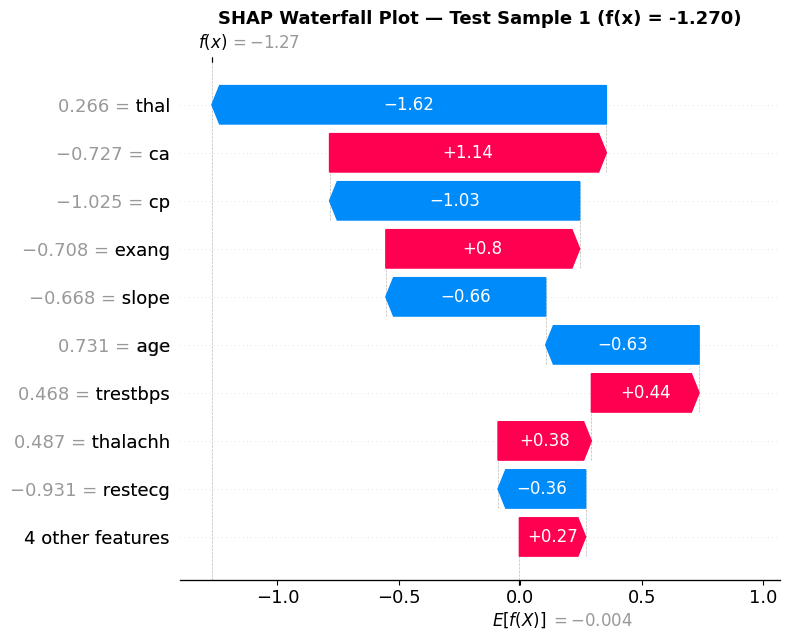

Saved: shap_waterfall_plot_test_sample.png


In [88]:
# SHAP Waterfall for a test-set patient (sample index 1)
sample_index = 1

sample  = X_test_scaled[sample_index].reshape(1, -1)
pred_s  = xgb.predict(sample)[0]
prob_s  = xgb.predict_proba(sample)[0]

print(f"Test sample {sample_index} — Prediction: {'Disease' if pred_s==1 else 'No Disease'}")
print(f"Probabilities: No Disease={prob_s[0]*100:.2f}%  Disease={prob_s[1]*100:.2f}%")

fx_s = shap_values[sample_index].base_values + shap_values[sample_index].values.sum()

plt.figure(figsize=(10, 8))
shap.plots.waterfall(shap_values[sample_index], show=False)
plt.title(f"SHAP Waterfall Plot — Test Sample {sample_index} (f(x) = {fx_s:.3f})",
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall_plot_test_sample.png', dpi=150, bbox_inches='tight')
plt.show()
plt.clf()
print("Saved: shap_waterfall_plot_test_sample.png")

## Download All Plots for Report

In [89]:
from google.colab import files
import zipfile, os

plot_files = [
    'heart_disease_distribution_new_data.png',
    'correlation_heatmap_new_data.png',
    'feature_distributions_new_data.png',
    'confusion_matrices_new_data.png',
    'model_accuracy_comparison_new_data.png',
    'shap_beeswarm_summary_plot_new_data.png',
    'shap_feature_importance_bar_plot_new_data.png',
    'shap_waterfall_plot_new_patient_new_data.png',
    'shap_waterfall_plot_test_sample.png',
]

zip_filename = 'heart_disease_plots.zip'
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for f in plot_files:
        if os.path.exists(f):
            zipf.write(f)
            print(f"Added {f} to {zip_filename}")
        else:
            print(f"Warning: {f} not found")

files.download(zip_filename)
print(f"\nDownloaded: {zip_filename}")

Added heart_disease_distribution_new_data.png to heart_disease_plots.zip
Added correlation_heatmap_new_data.png to heart_disease_plots.zip
Added feature_distributions_new_data.png to heart_disease_plots.zip
Added confusion_matrices_new_data.png to heart_disease_plots.zip
Added model_accuracy_comparison_new_data.png to heart_disease_plots.zip
Added shap_beeswarm_summary_plot_new_data.png to heart_disease_plots.zip
Added shap_feature_importance_bar_plot_new_data.png to heart_disease_plots.zip
Added shap_waterfall_plot_new_patient_new_data.png to heart_disease_plots.zip
Added shap_waterfall_plot_test_sample.png to heart_disease_plots.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Downloaded: heart_disease_plots.zip
